In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("../data")
data_dir.mkdir(exist_ok=True)
url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet"
file_path = data_dir / "yellow_tripdata_2026-05.parquet"

if not file_path.exists():
    urlretrieve(url, file_path)

file_path

PosixPath('../data/yellow_tripdata_2026-05.parquet')

In [3]:
data_path = Path("../data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path


PosixPath('../data/yellow_tripdata_2026-05.parquet')

In [4]:
df = pd.read_parquet(data_path)
df.shape
df.dtypes
df["payment_type"] =  df["payment_type"].astype("int32")

In [5]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int32
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

In [6]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
]

df[columns].head()


,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2026-05-01 00:04:59,2026-05-01 00:32:48,138,37,7.51
1,2026-05-01 00:37:05,2026-05-01 00:59:47,138,237,6.14
2,2026-05-01 00:34:05,2026-05-01 00:54:02,249,232,2.40
3,2026-05-01 00:55:07,2026-05-01 01:02:43,232,114,1.20
4,2026-05-01 00:44:13,2026-05-01 00:44:13,140,237,0.86


In [7]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()


count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

In [8]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)


In [9]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)


(160000, 40000)

In [10]:

import numpy as np
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)


y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape
for X in (X_train, X_val):
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)

print(X_train.indices.dtype, X_train.indptr.dtype)

int32 int32


In [11]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse


6.652815344851184

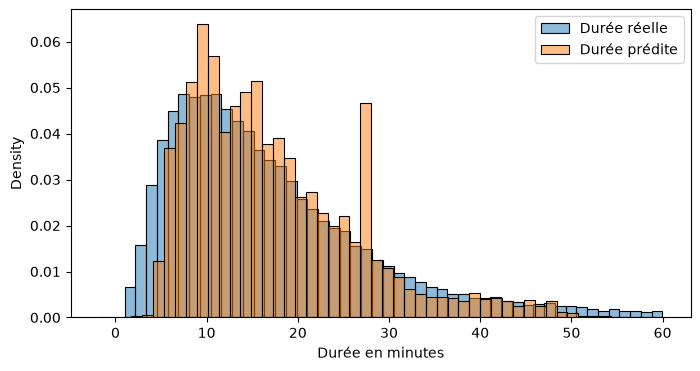

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5,
)
plt.xlabel("Durée en minutes")
plt.legend()
plt.show()


In [13]:
lasso_model = Lasso(alpha=0.01, max_iter=5_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse


10.517043400486218

In [14]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse


6.471618951707119

In [15]:
results = pd.DataFrame(
    {
        "model": ["LinearRegression", "Lasso", "XGBoost"],
        "rmse": [linear_rmse, lasso_rmse, xgb_rmse],
    }
).sort_values("rmse")

results


,model,rmse
2,XGBoost,6.471619
0,LinearRegression,6.652815
1,Lasso,10.517043


In [16]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse),
}

selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path


('XGBoost', 6.471618951707119, PosixPath('models/duration_model.bin'))

In [17]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
example_matrix = loaded_dv.transform(example)
prediction = loaded_model.predict(example_matrix)[0]

prediction


np.float32(21.65231)

### Exercice
## Modifier XGB sur learning_rate

In [27]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.3,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse


6.398215325659547

In [ ]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse),
}

selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model3.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path


In [ ]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
example_matrix = loaded_dv.transform(example)
prediction = loaded_model.predict(example_matrix)[0]

prediction

### LASSO

In [21]:
lasso_model = Lasso(alpha=0.02, max_iter=5_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse


10.847949996588278

In [22]:
lasso_model = Lasso(alpha=0.03, max_iter=5_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

10.905126839479646

# Alpha 0.03
- 10.905126839479646
# Alpha 0.02
- 10.847949996588278
# Alpha 0.01
- 10.517043400486218

### On obtiente la valeur la plus faible avec l'arbre XBG 
### en jouant avec le learning_rated, on obtient de meilleurs résultats
### les parametres de préditions, les valeurs entrainées

In [29]:
import mlflow
print("test")
print(mlflow.get_tracking_uri())


test
sqlite:////workspaces/learning-mlops/notebooks/mlflow.db


In [30]:
mlflow.set_experiment("nyc-taxi-duration")

<Experiment: artifact_location='/workspaces/learning-mlops/notebooks/mlruns/1', creation_time=1795785043157, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795785043157, lifecycle_stage='active', name='nyc-taxi-duration', tags={}, trace_location=None, workspace='default'>

In [32]:
with mlflow.start_run():
    mlflow.set_tag("task", "taxi-duration-prediction")
    mlflow.log_param("model", selected_name)
    mlflow.log_param("sample_size", sample_size)
    mlflow.log_param("validation_ratio", 0.2)
    mlflow.log_metric("validation_rmse", selected_rmse)

    mlflow.sklearn.log_model(
        sk_model=selected_model,
        name="model",
            skops_trusted_types=[
        "xgboost.core.Booster",
        "xgboost.sklearn.XGBRegressor",
    ],
    )


In [39]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5001")
mlflow.set_experiment("nyc-taxi-duration")

print(mlflow.get_tracking_uri())

MlflowException: API request to http://127.0.0.1:5001/api/2.0/mlflow/experiments/get-by-name failed with exception HTTPConnectionPool(host='127.0.0.1', port=5001): Max retries exceeded with url: /api/2.0/mlflow/experiments/get-by-name?experiment_name=nyc-taxi-duration (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=5001): Failed to establish a new connection: [Errno 111] Connection refused"))

In [ ]:
with mlflow.start_run():
    mlflow.set_tag("task", "taxi-duration-prediction")
    mlflow.log_param("model", selected_name)
    mlflow.log_param("sample_size", sample_size)
    mlflow.log_param("validation_ratio", 0.2)
    mlflow.log_metric("validation_rmse", selected_rmse)

    mlflow.sklearn.log_model(
        sk_model=selected_model,
        name=selected_name,
    )


In [38]:
print("test")

test
